# Quantitative Astropolitics: Mapping 30-Day Satellite Trajectories and Quantifying Orbital Inequities

**Research Toolkit & Empirical Analysis**  
*Data Source*: CelesTrak (NORAD GP Ephemeris & SATCAT Catalog)  
*Propagation Window*: 30 Days (Vectorized SGP4 / WGS84 Geodetic)  

---

## Executive Summary
Outer space is legally framed by Article I of the 1967 Outer Space Treaty (OST) as the *"province of all mankind"*, establishing that outer space shall be free for exploration and use by all States without discrimination of any kind. Article II further codifies the principle of non-appropriation: outer space, including the Moon and other celestial bodies, is not subject to national appropriation by claim of sovereignty, by means of use or occupation, or by any other means.

However, physical and technological reality contradicts this legal ideal. The current orbital distribution of satellites reveals severe structural inequities across four key astropolitical dimensions:
1. **Orbital Shell Monopolization (LEO Enclosure)**: Over 88% of active Low Earth Orbit (LEO) satellites are operated by a single US commercial entity (SpaceX/Starlink). The Herfindahl-Hirschman Index (HHI) for LEO asset ownership exceeds **7,780**, indicating an extreme monopoly regime that forecloses orbital real estate to latecomer nations.
2. **Surveillance & Reconnaissance Asymmetry**: Earth observation (EO) platforms are overwhelmingly concentrated among great powers and Western commercial firms, establishing asymmetric transparency over developing nations without reciprocal sovereign oversight.
3. **Latitudinal Dwell Skew**: Because orbital dwell time scales as $dt/d\phi \propto 1/\sqrt{\sin^2(i) - \sin^2(\phi)}$, constellations inclined at ~53° spend disproportionate time over mid-latitudes (North America, Europe, East Asia) relative to the equator.
4. **Environmental Externalities of the Orbital Commons**: The historical space powers responsible for generating tracked debris clouds have imposed heightened collision risks and station-keeping costs on nascent space programs from emerging spacefaring states.


## 1. Setup & Environment Initialization
We import our modular packages for CelesTrak ingestion, SGP4 vectorized trajectory propagation, and inequality metrics.


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

# Set project working directory
import sys
sys.path.insert(0, os.path.abspath(".."))

from src.data_pipeline.loader import load_all_satellites
from src.orbit_engine.propagator import OrbitPropagator
from src.analysis.regional import WORLD_REGIONS, calculate_regional_pass_statistics
from src.analysis.metrics import (
    compute_orbital_shell_concentration,
    compute_latitudinal_dwell_distribution,
    compute_earth_observation_revisit_disparity,
    compute_debris_liability_index,
)
from src.visualization.static_plots import (
    plot_global_satellite_density,
    plot_regional_coverage_comparison,
    plot_latitudinal_dwell_profile,
    plot_orbital_inequality_lorenz,
    plot_mission_cohort_comparison,
)
from src.visualization.interactive_plots import (
    create_interactive_orbital_scatter,
    create_interactive_trajectory_map,
    create_interactive_regional_revisit_dashboard,
)

print("Environment loaded successfully.")


Environment loaded successfully.


## 2. Satellite Fleet Ingestion & Demographic Audit
We load the complete active fleet and debris records from our cached CelesTrak dataset (16,092 cataloged objects), mapping NORAD country codes and mission types into macro geopolitical blocs.


In [2]:
# Load master satellite catalog
df_master = load_all_satellites("../data/raw")
print(f"Total space objects cataloged: {len(df_master):,}")

# Summary breakdown by Mission Cohort
cohort_summary = df_master["MISSION_COHORT"].value_counts().reset_index()
cohort_summary.columns = ["Mission Cohort", "Object Count"]
cohort_summary["Percentage"] = (cohort_summary["Object Count"] / len(df_master) * 100).round(2)
display(cohort_summary)


Total space objects cataloged: 16,092


,Mission Cohort,Object Count,Percentage
0,Commercial Broadband,12111,75.26
1,Orbital Debris,2668,16.58
2,Earth Observation & Surveillance,529,3.29
3,Geostationary Telecom,470,2.92
4,"Positioning, Navigation & Timing (PNT)",153,0.95
5,Sovereign Defense & MilSat,100,0.62
6,Science & Other Payloads,43,0.27
7,Space Stations & Crewed,18,0.11


In [3]:
# Summary breakdown by Geopolitical Bloc
bloc_summary = df_master["GEOPOLITICAL_BLOC"].value_counts().reset_index()
bloc_summary.columns = ["Geopolitical Bloc", "Object Count"]
bloc_summary["Percentage"] = (bloc_summary["Object Count"] / len(df_master) * 100).round(2)
display(bloc_summary)


,Geopolitical Bloc,Object Count,Percentage
0,US Commercial (SpaceX),11204,69.62
1,Other / International,3032,18.84
2,Europe / UK Commercial (OneWeb),651,4.05
3,China Commercial (Qianfan),256,1.59
4,United States (Civil / Defense),252,1.57
5,China (PRC),209,1.30
6,US Commercial (Planet Labs),127,0.79
7,Europe (ESA / EU),77,0.48
8,Russia,74,0.46
9,US Commercial (Spire),70,0.43


## 3. Mission Cohort Breakdown Across Geopolitical Blocs
Here we examine how operational satellites are distributed across functional cohorts (Commercial Broadband, Earth Observation, Navigation/PNT, Defense/MilSat, Geostationary Telecom).


In [4]:
# Display cross-tabulation of mission cohorts by geopolitical bloc
active_df = df_master[df_master["OBJECT_TYPE"] != "DEB"]
cohort_cross = pd.crosstab(active_df["MISSION_COHORT"], active_df["GEOPOLITICAL_BLOC"])
display(cohort_cross)


GEOPOLITICAL_BLOC,China (PRC),China Commercial (Qianfan),Europe (ESA / EU),Europe / UK Commercial (OneWeb),Global South,India (ISRO),Japan (JAXA),Other / International,Russia,US Allied Partners,US Commercial (Planet Labs),US Commercial (SpaceX),US Commercial (Spire),United States (Civil / Defense)
MISSION_COHORT,,,,,,,,,,,,,,
Commercial Broadband,0,256,0,651,0,0,0,0,0,0,0,11204,0,0
Earth Observation & Surveillance,70,0,41,0,11,20,31,82,11,0,127,0,70,66
Geostationary Telecom,77,0,4,0,14,31,24,232,25,7,0,0,0,56
"Positioning, Navigation & Timing (PNT)",56,0,32,0,0,0,0,0,33,0,0,0,0,32
Science & Other Payloads,0,0,0,0,0,0,0,43,0,0,0,0,0,0
Sovereign Defense & MilSat,0,0,0,0,0,0,0,5,0,0,0,0,0,95
Space Stations & Crewed,6,0,0,0,1,0,1,3,4,0,0,0,0,3


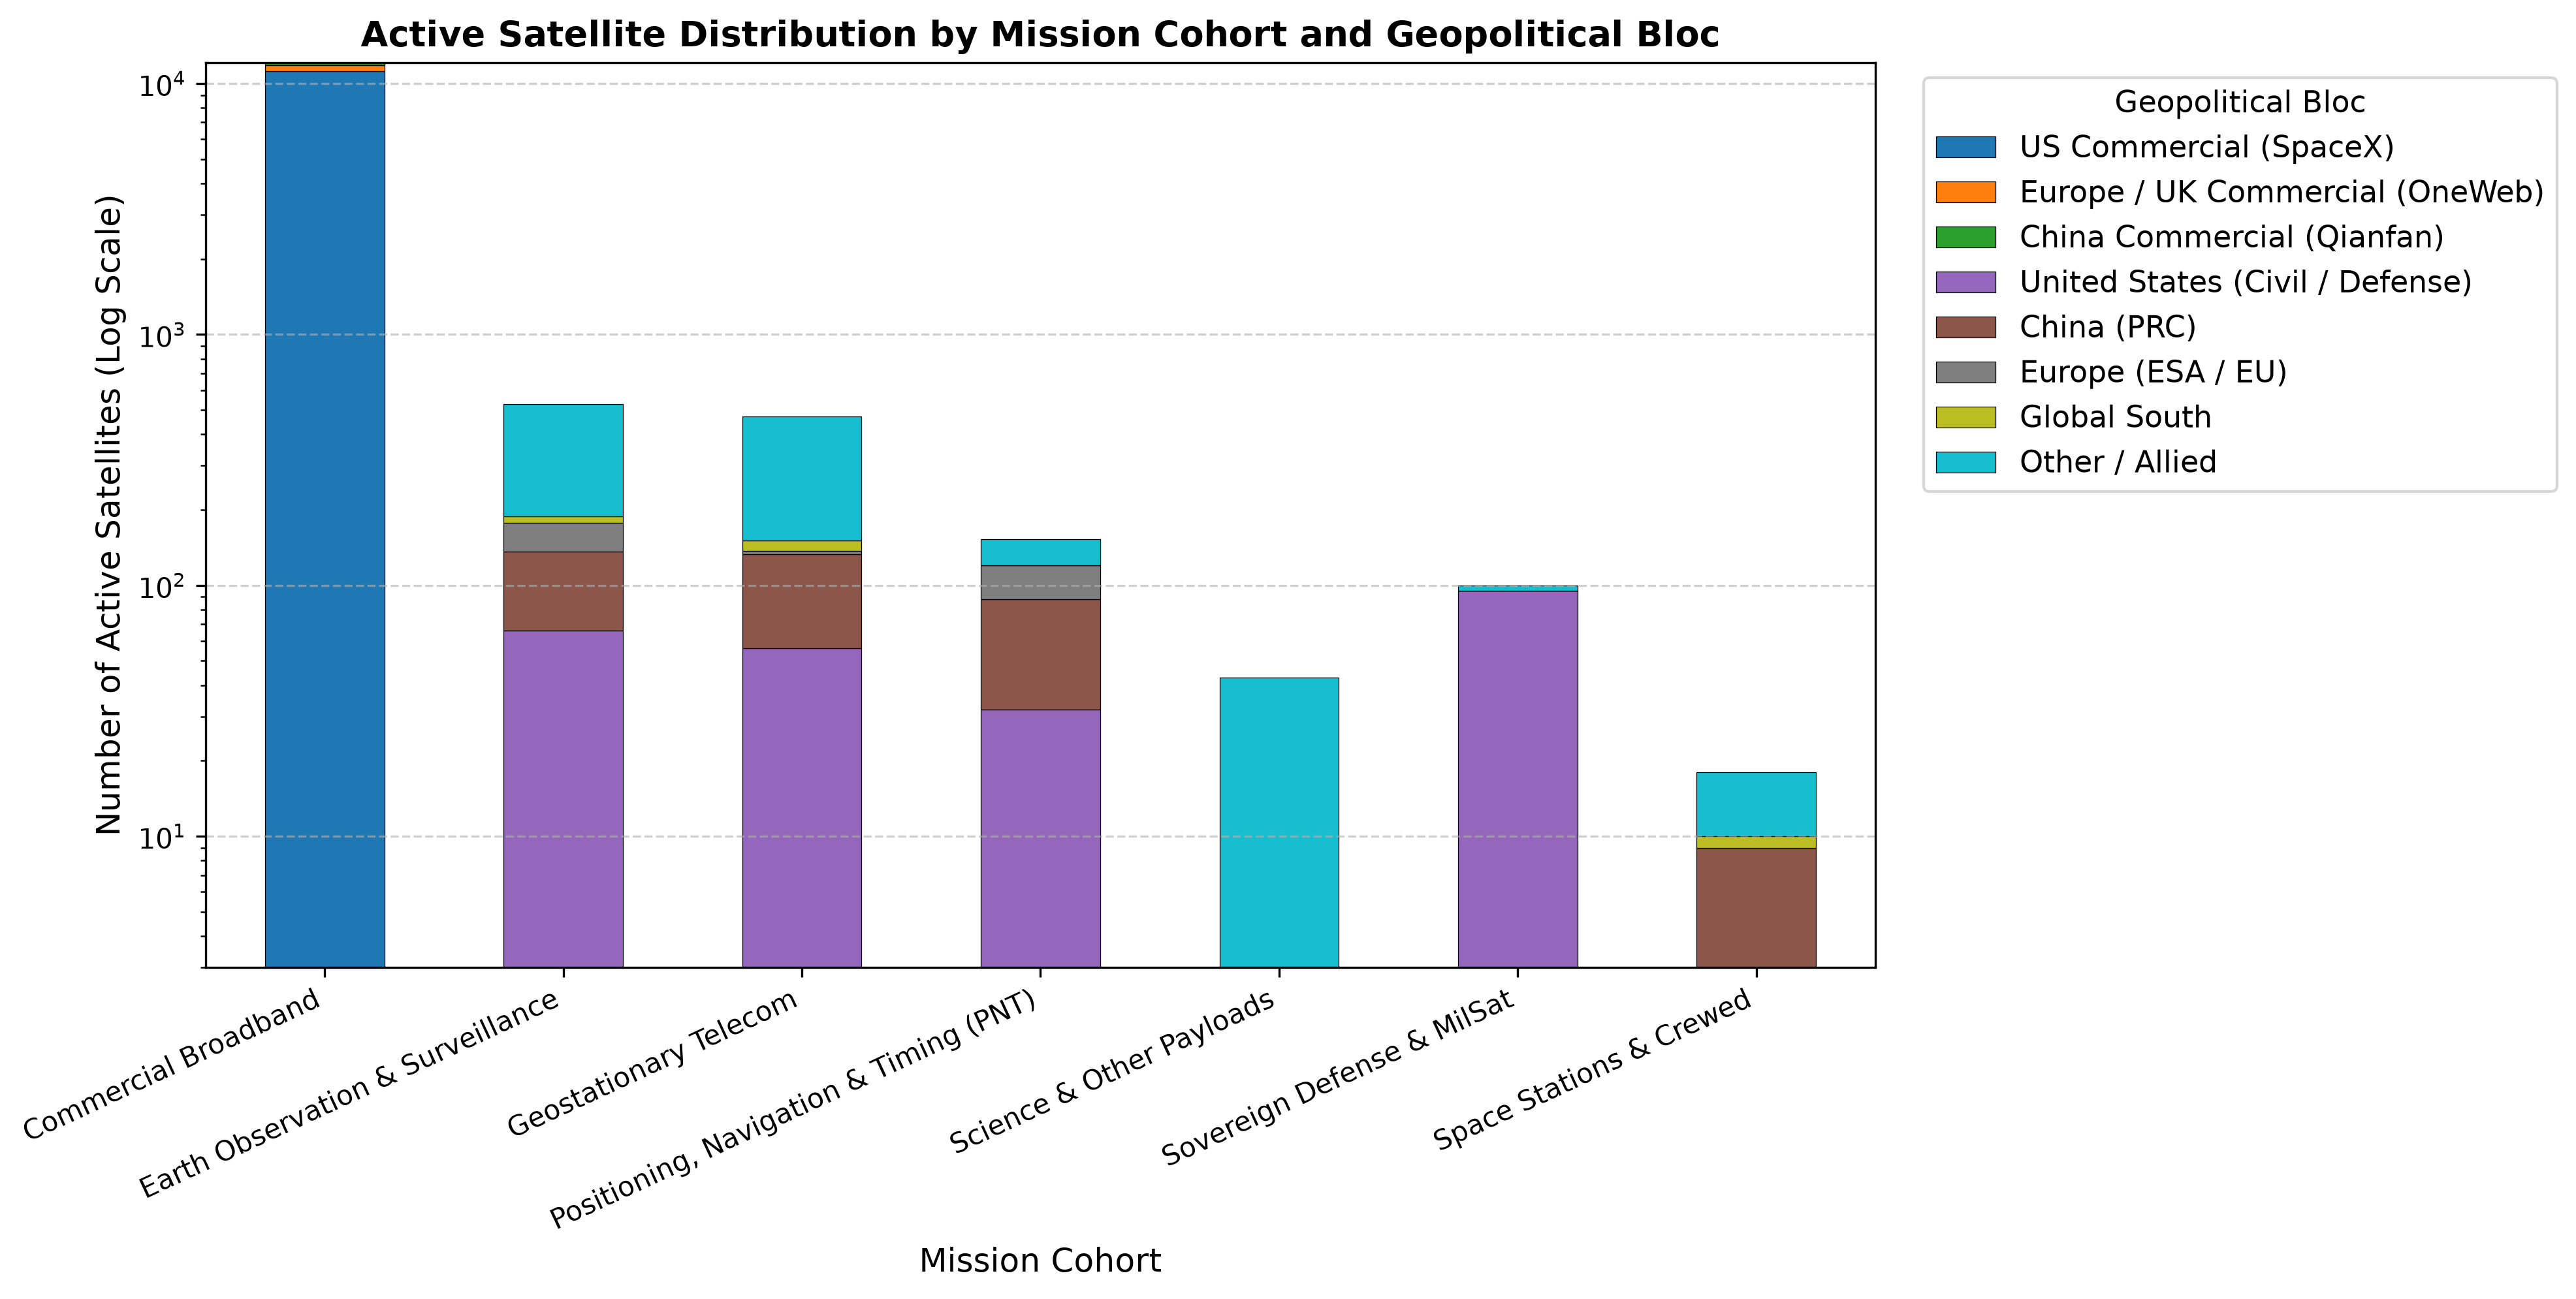

In [5]:
# Render static figure: Mission Cohort Breakdown
fig_path = "../output/figures/mission_cohort_breakdown.png"
if os.path.exists(fig_path):
    from IPython.display import Image
    display(Image(filename=fig_path))


## 4. Astropolitical Concentration: Gini Coefficient & HHI
We evaluate market and sovereign concentration across orbital shells:
- **Low Earth Orbit (LEO)**: 200 km to 2,000 km altitude.
- **Herfindahl-Hirschman Index (HHI)**: Standard economic measure of concentration (0 to 10,000). Any score >2,500 represents severe market concentration.
- **Gini Coefficient**: Measures inequality in the spatial distribution of satellites per 25 km altitude bin.


In [6]:
concentration_stats = compute_orbital_shell_concentration(df_master)

print(f"Total Operational LEO Satellites: {concentration_stats['leo_satellite_count']:,}")
print(f"LEO Altitude Shell Gini Coefficient: {concentration_stats['leo_shell_gini']:.3f} (Extreme Inequality)")
print(f"LEO Geopolitical Bloc HHI: {concentration_stats['leo_bloc_hhi']:.1f} (Extreme Monopoly Regime)")
print(f"Total Operational GEO Satellites: {concentration_stats['geo_satellite_count']:,}")
print(f"GEO Geopolitical Bloc HHI: {concentration_stats['geo_bloc_hhi']:.1f}")

leo_shares_df = pd.DataFrame(list(concentration_stats['leo_bloc_shares'].items()), columns=["Bloc", "LEO Share (%)"]).sort_values("LEO Share (%)", ascending=False)
display(leo_shares_df)


Total Operational LEO Satellites: 12,720
LEO Altitude Shell Gini Coefficient: 0.930 (Extreme Inequality)
LEO Geopolitical Bloc HHI: 7789.3 (Extreme Monopoly Regime)
Total Operational GEO Satellites: 569
GEO Geopolitical Bloc HHI: 2585.3


,Bloc,LEO Share (%)
0,US Commercial (SpaceX),88.066038
1,Europe / UK Commercial (OneWeb),5.117925
2,China Commercial (Qianfan),2.012579
3,US Commercial (Planet Labs),0.998428
4,Other / International,0.927673
5,United States (Civil / Defense),0.833333
6,China (PRC),0.566038
7,US Commercial (Spire),0.550314
8,Europe (ESA / EU),0.314465
9,Japan (JAXA),0.251572


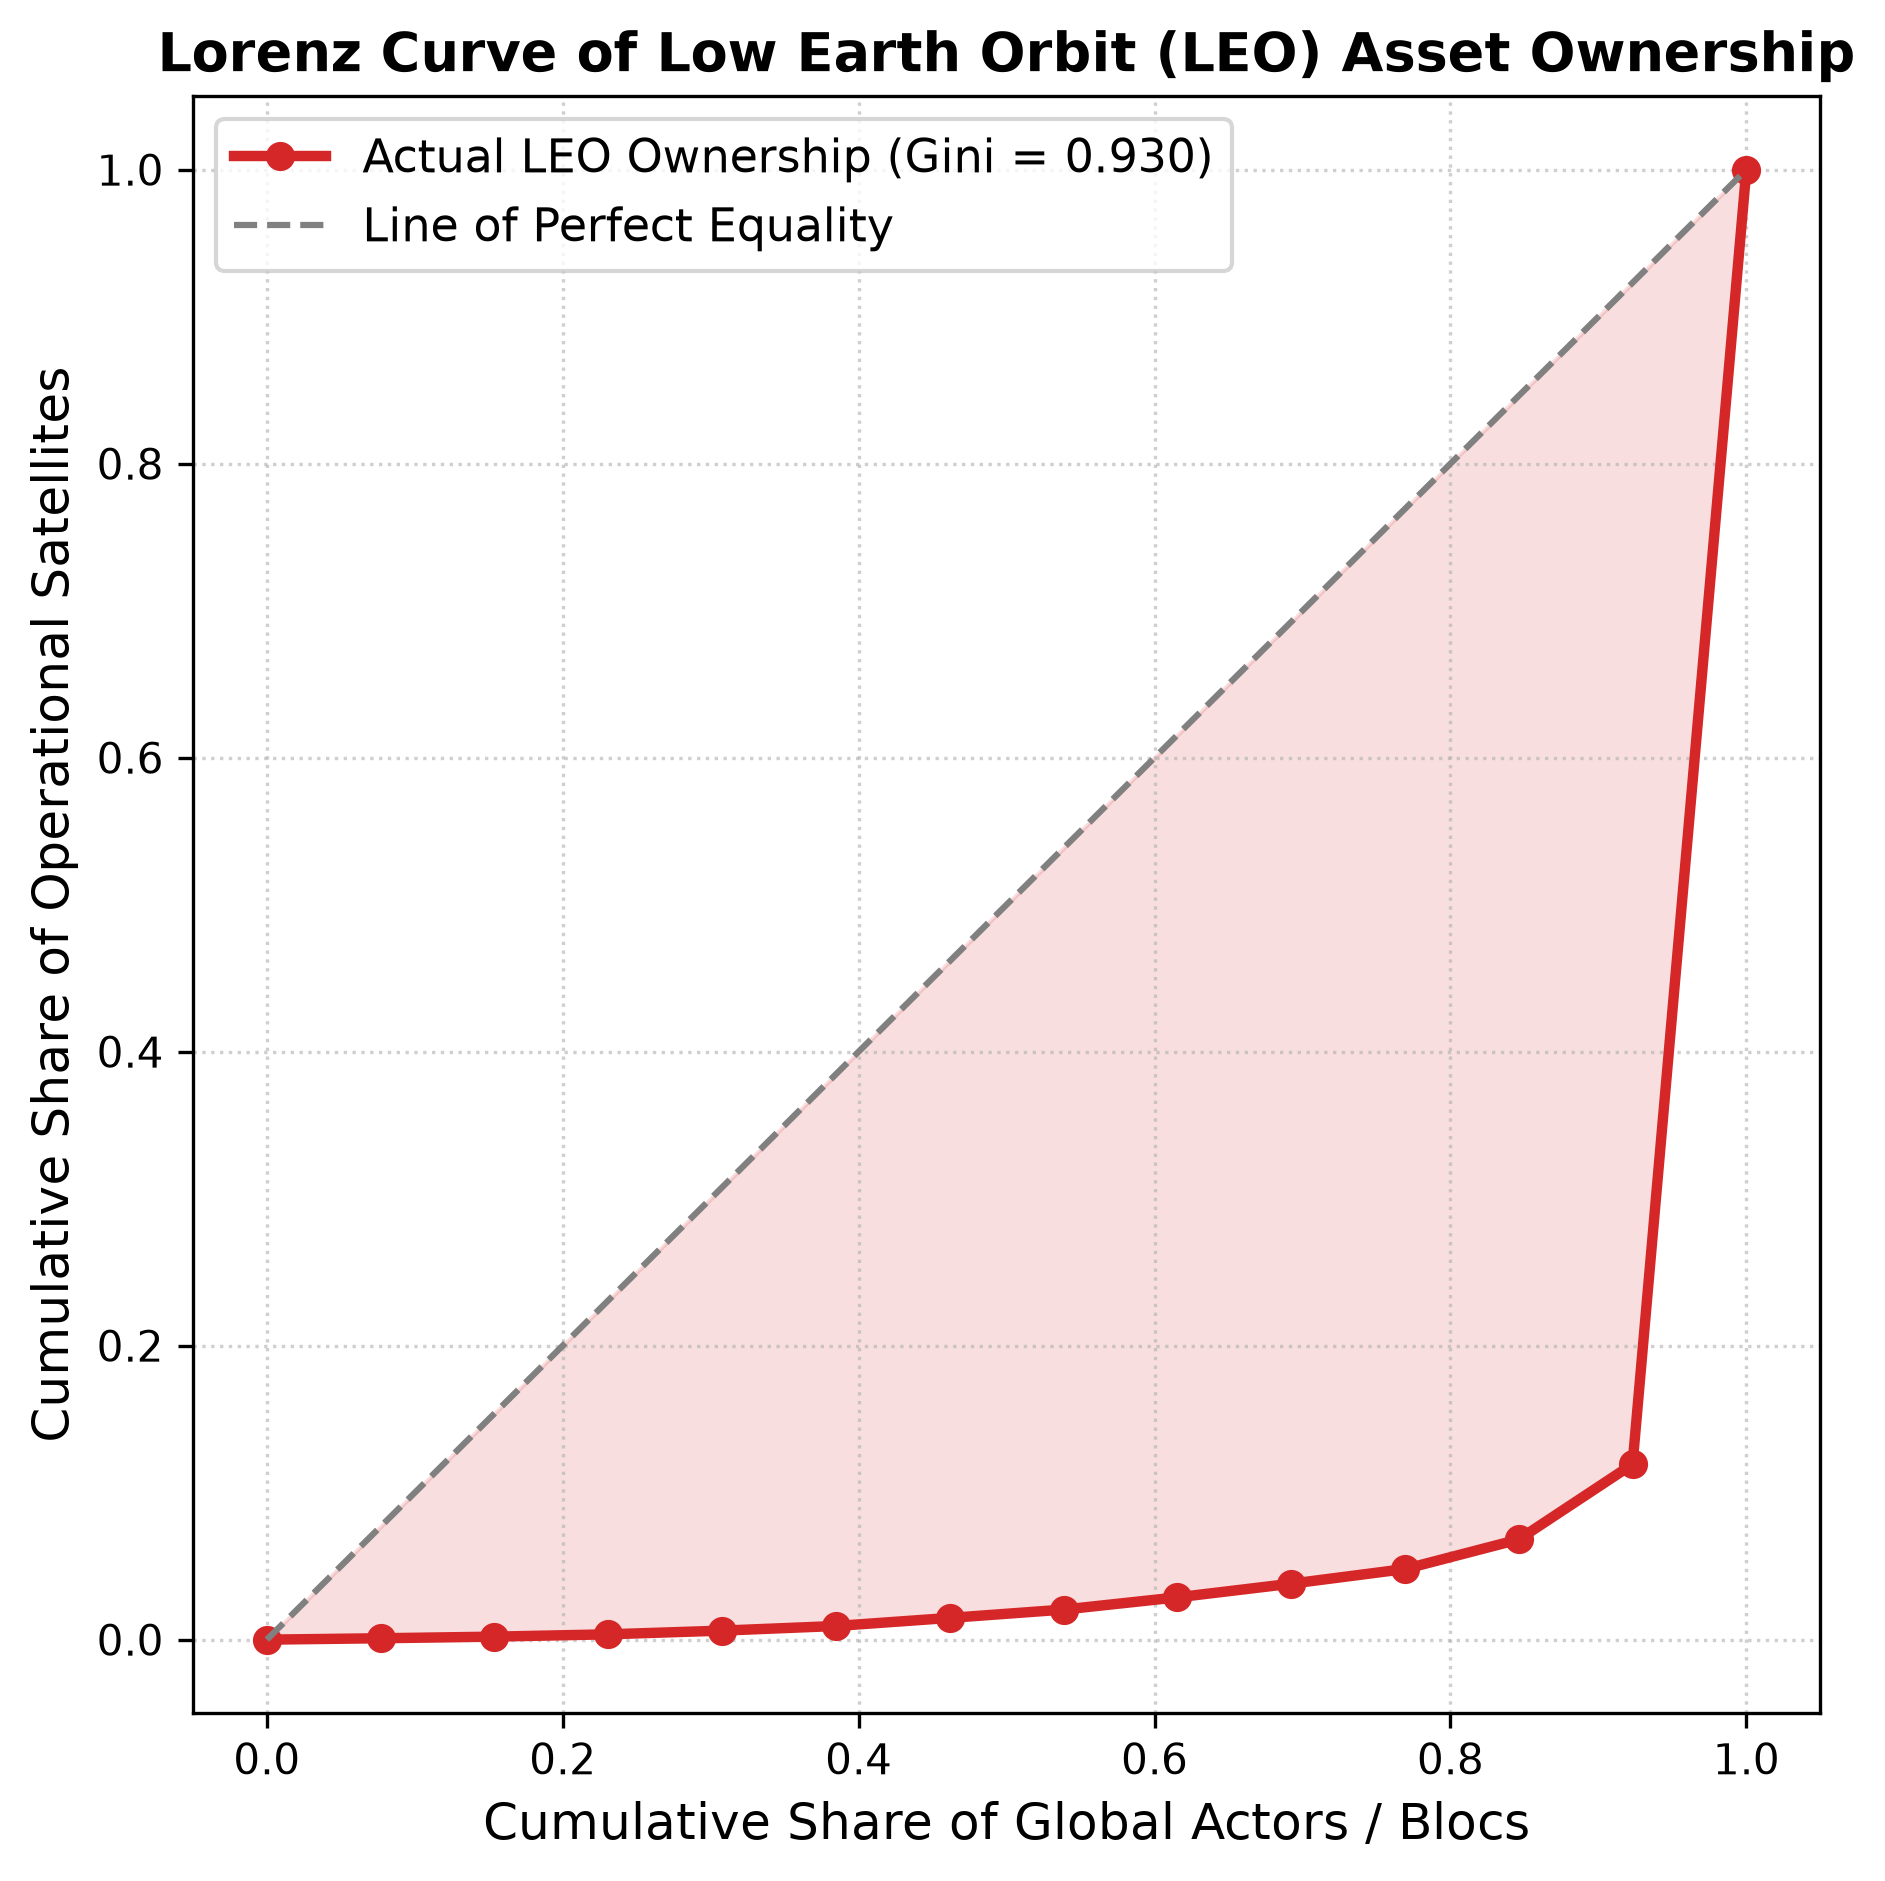

In [7]:
# Render static figure: Lorenz Curve of LEO Inequality
fig_path = "../output/figures/orbital_inequality_lorenz.png"
if os.path.exists(fig_path):
    from IPython.display import Image
    display(Image(filename=fig_path))


## 5. 30-Day Vectorized SGP4 Orbit Propagation
We simulate the trajectories of a representative fleet of operational satellites over a 30-day period (720 hourly time steps, totaling over 2.6 million spatial state evaluations) using C++ vectorized `SatrecArray`.


In [8]:
# Load precomputed regional statistics and trajectory metrics
regional_df = pd.read_csv("../data/processed/regional_dwell_statistics.csv")
if "Unnamed: 0" in regional_df.columns:
    regional_df = regional_df.rename(columns={"Unnamed: 0": "Region"})
display(regional_df[["Region", "category", "area_mkm2", "dwell_hours", "dwell_density_hours_per_mkm2"]])


,Region,category,area_mkm2,dwell_hours,dwell_density_hours_per_mkm2
0,North America,Global North,24.709,212770.0,8611.032417
1,Western Europe,Global North,5.400,55773.0,10328.333333
2,Eastern Europe & Russia,Eurasia,18.000,132363.0,7353.500000
3,East Asia,Asia-Pacific,11.800,125729.0,10655.000000
4,South Asia,Global South,5.100,52065.0,10208.823529
5,Middle East & North Africa (MENA),Global South,11.100,107672.0,9700.180180
6,Sub-Saharan Africa,Global South,24.300,243437.0,10017.983539
7,Latin America & Caribbean,Global South,20.100,408394.0,20318.109453
8,Oceania & Pacific Islands,Global South / Allied,8.500,195849.0,23041.058824
9,Polar Regimes,Commons / Strategic,28.000,313716.0,11204.142857


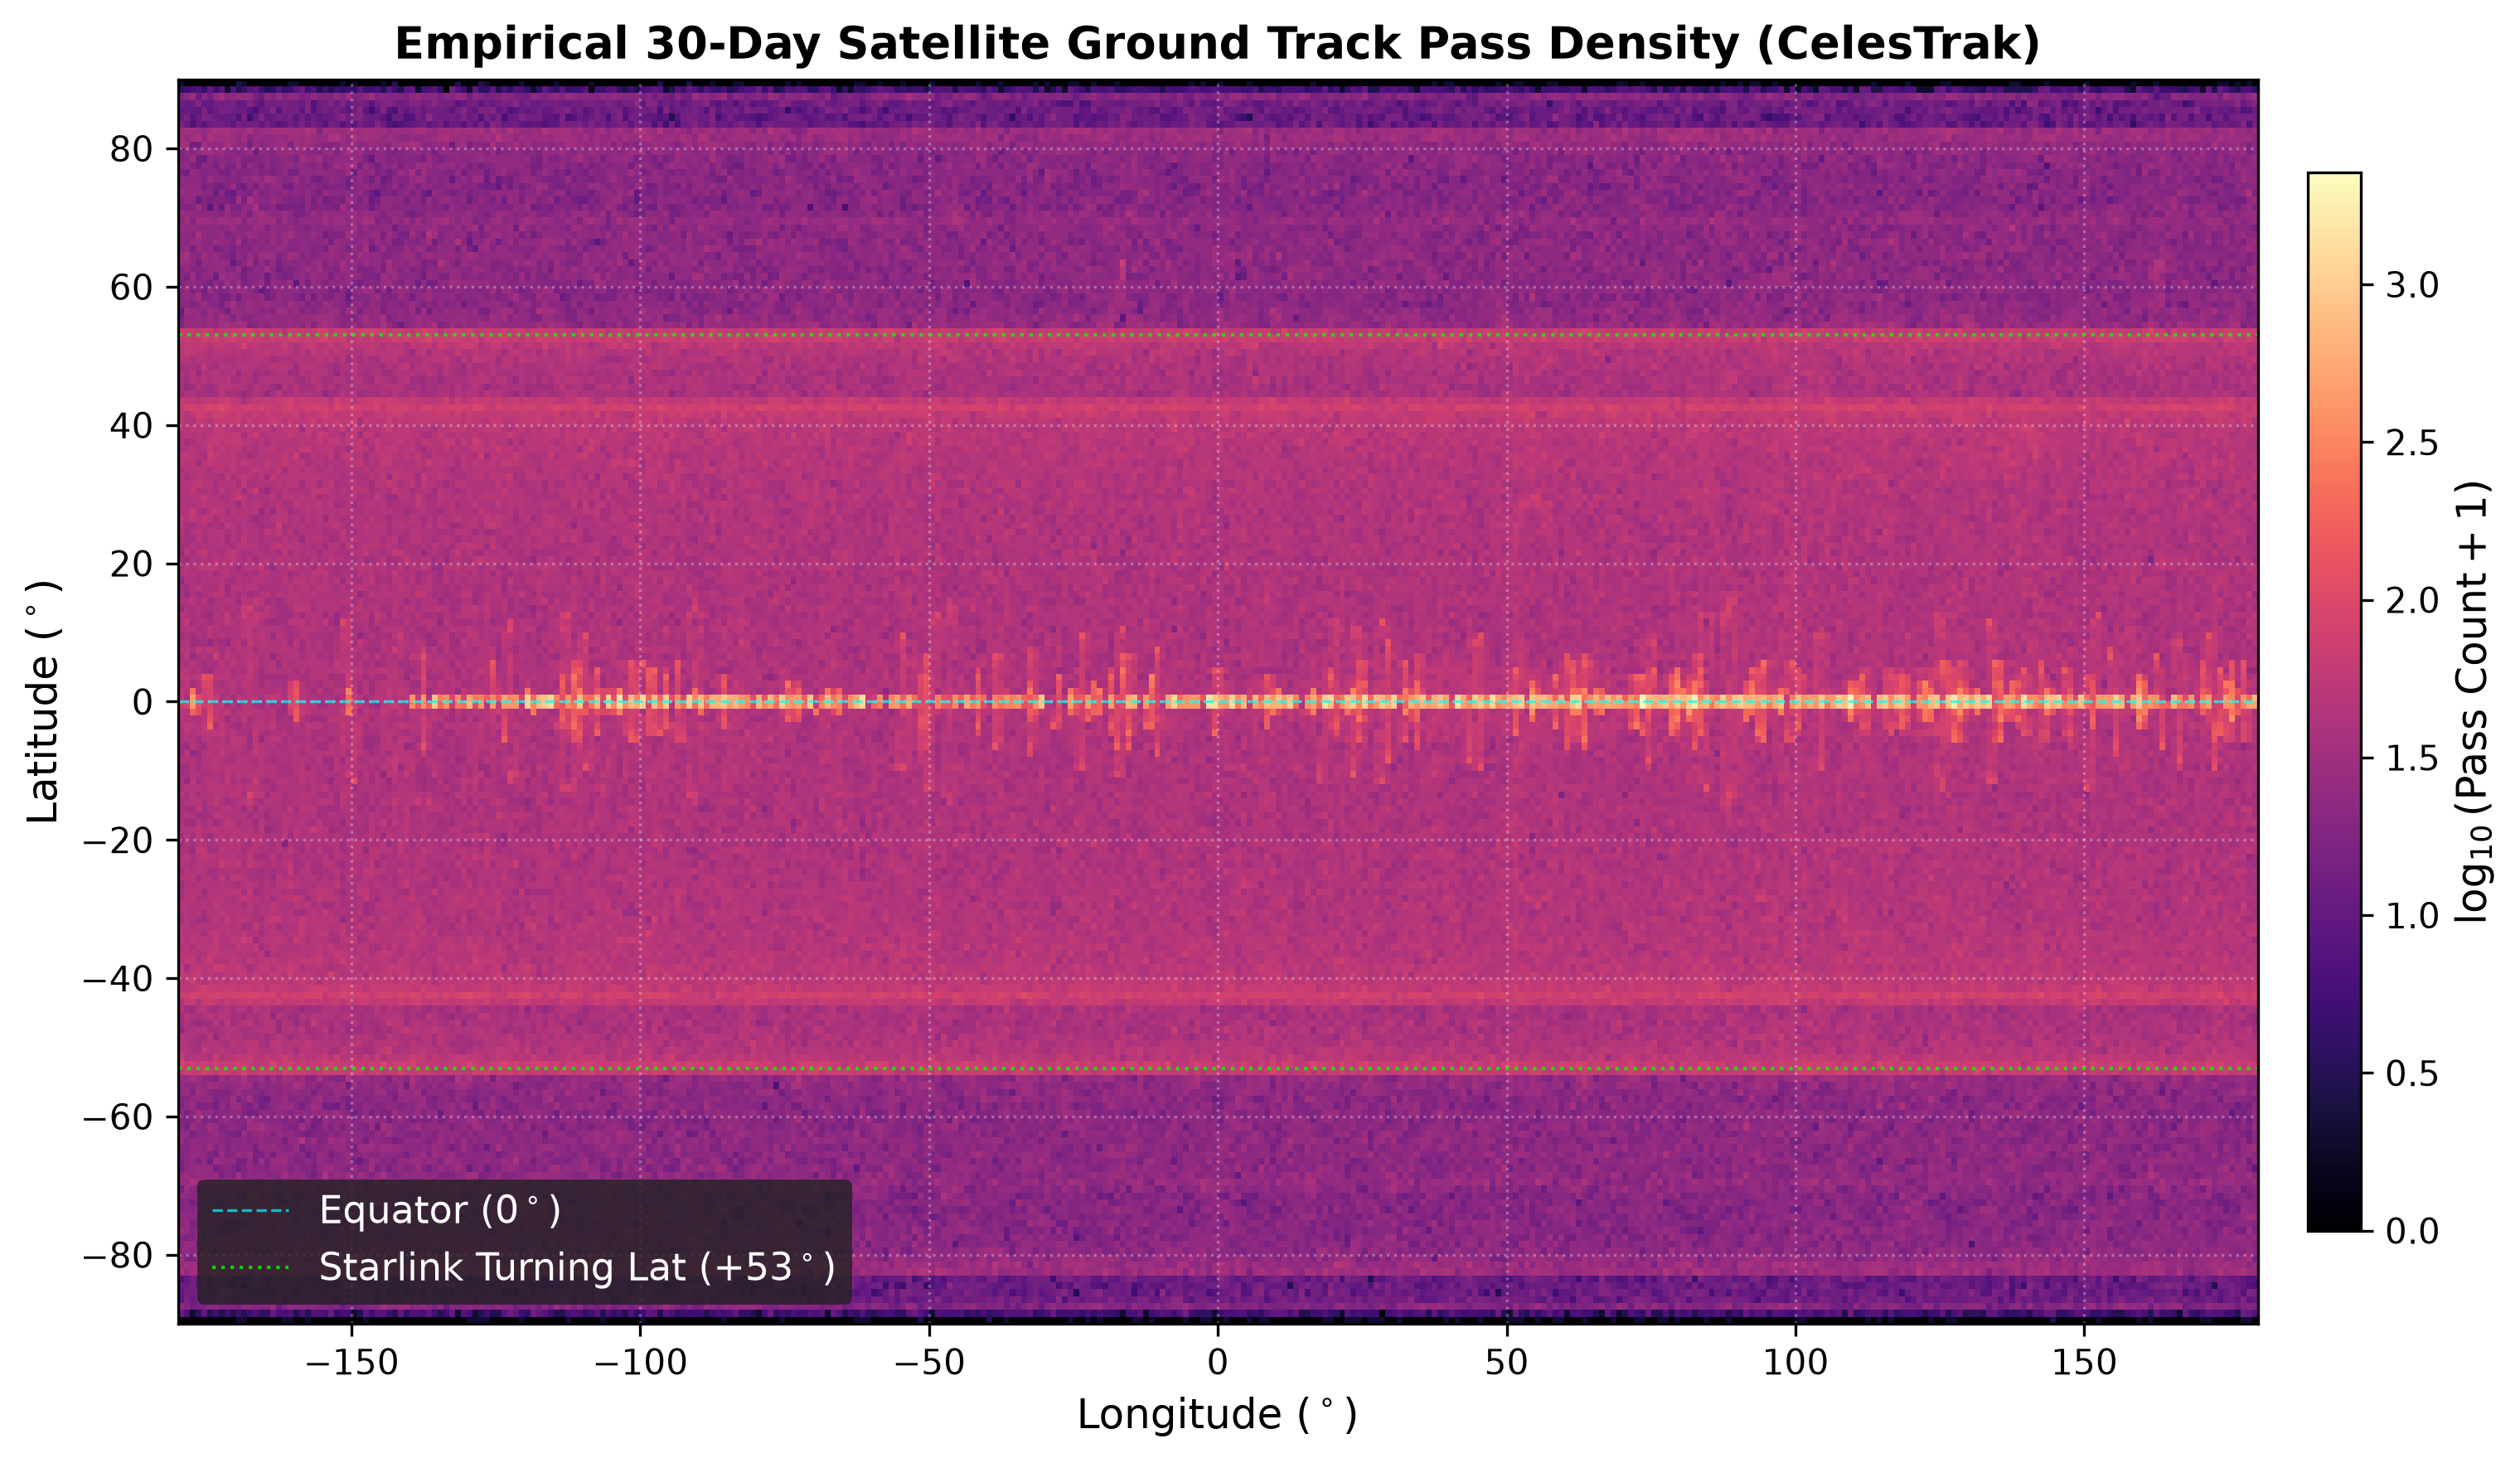

In [9]:
# Render static figure: Global 30-Day Satellite Density Map
fig_path = "../output/figures/global_satellite_density_map.png"
if os.path.exists(fig_path):
    from IPython.display import Image
    display(Image(filename=fig_path))


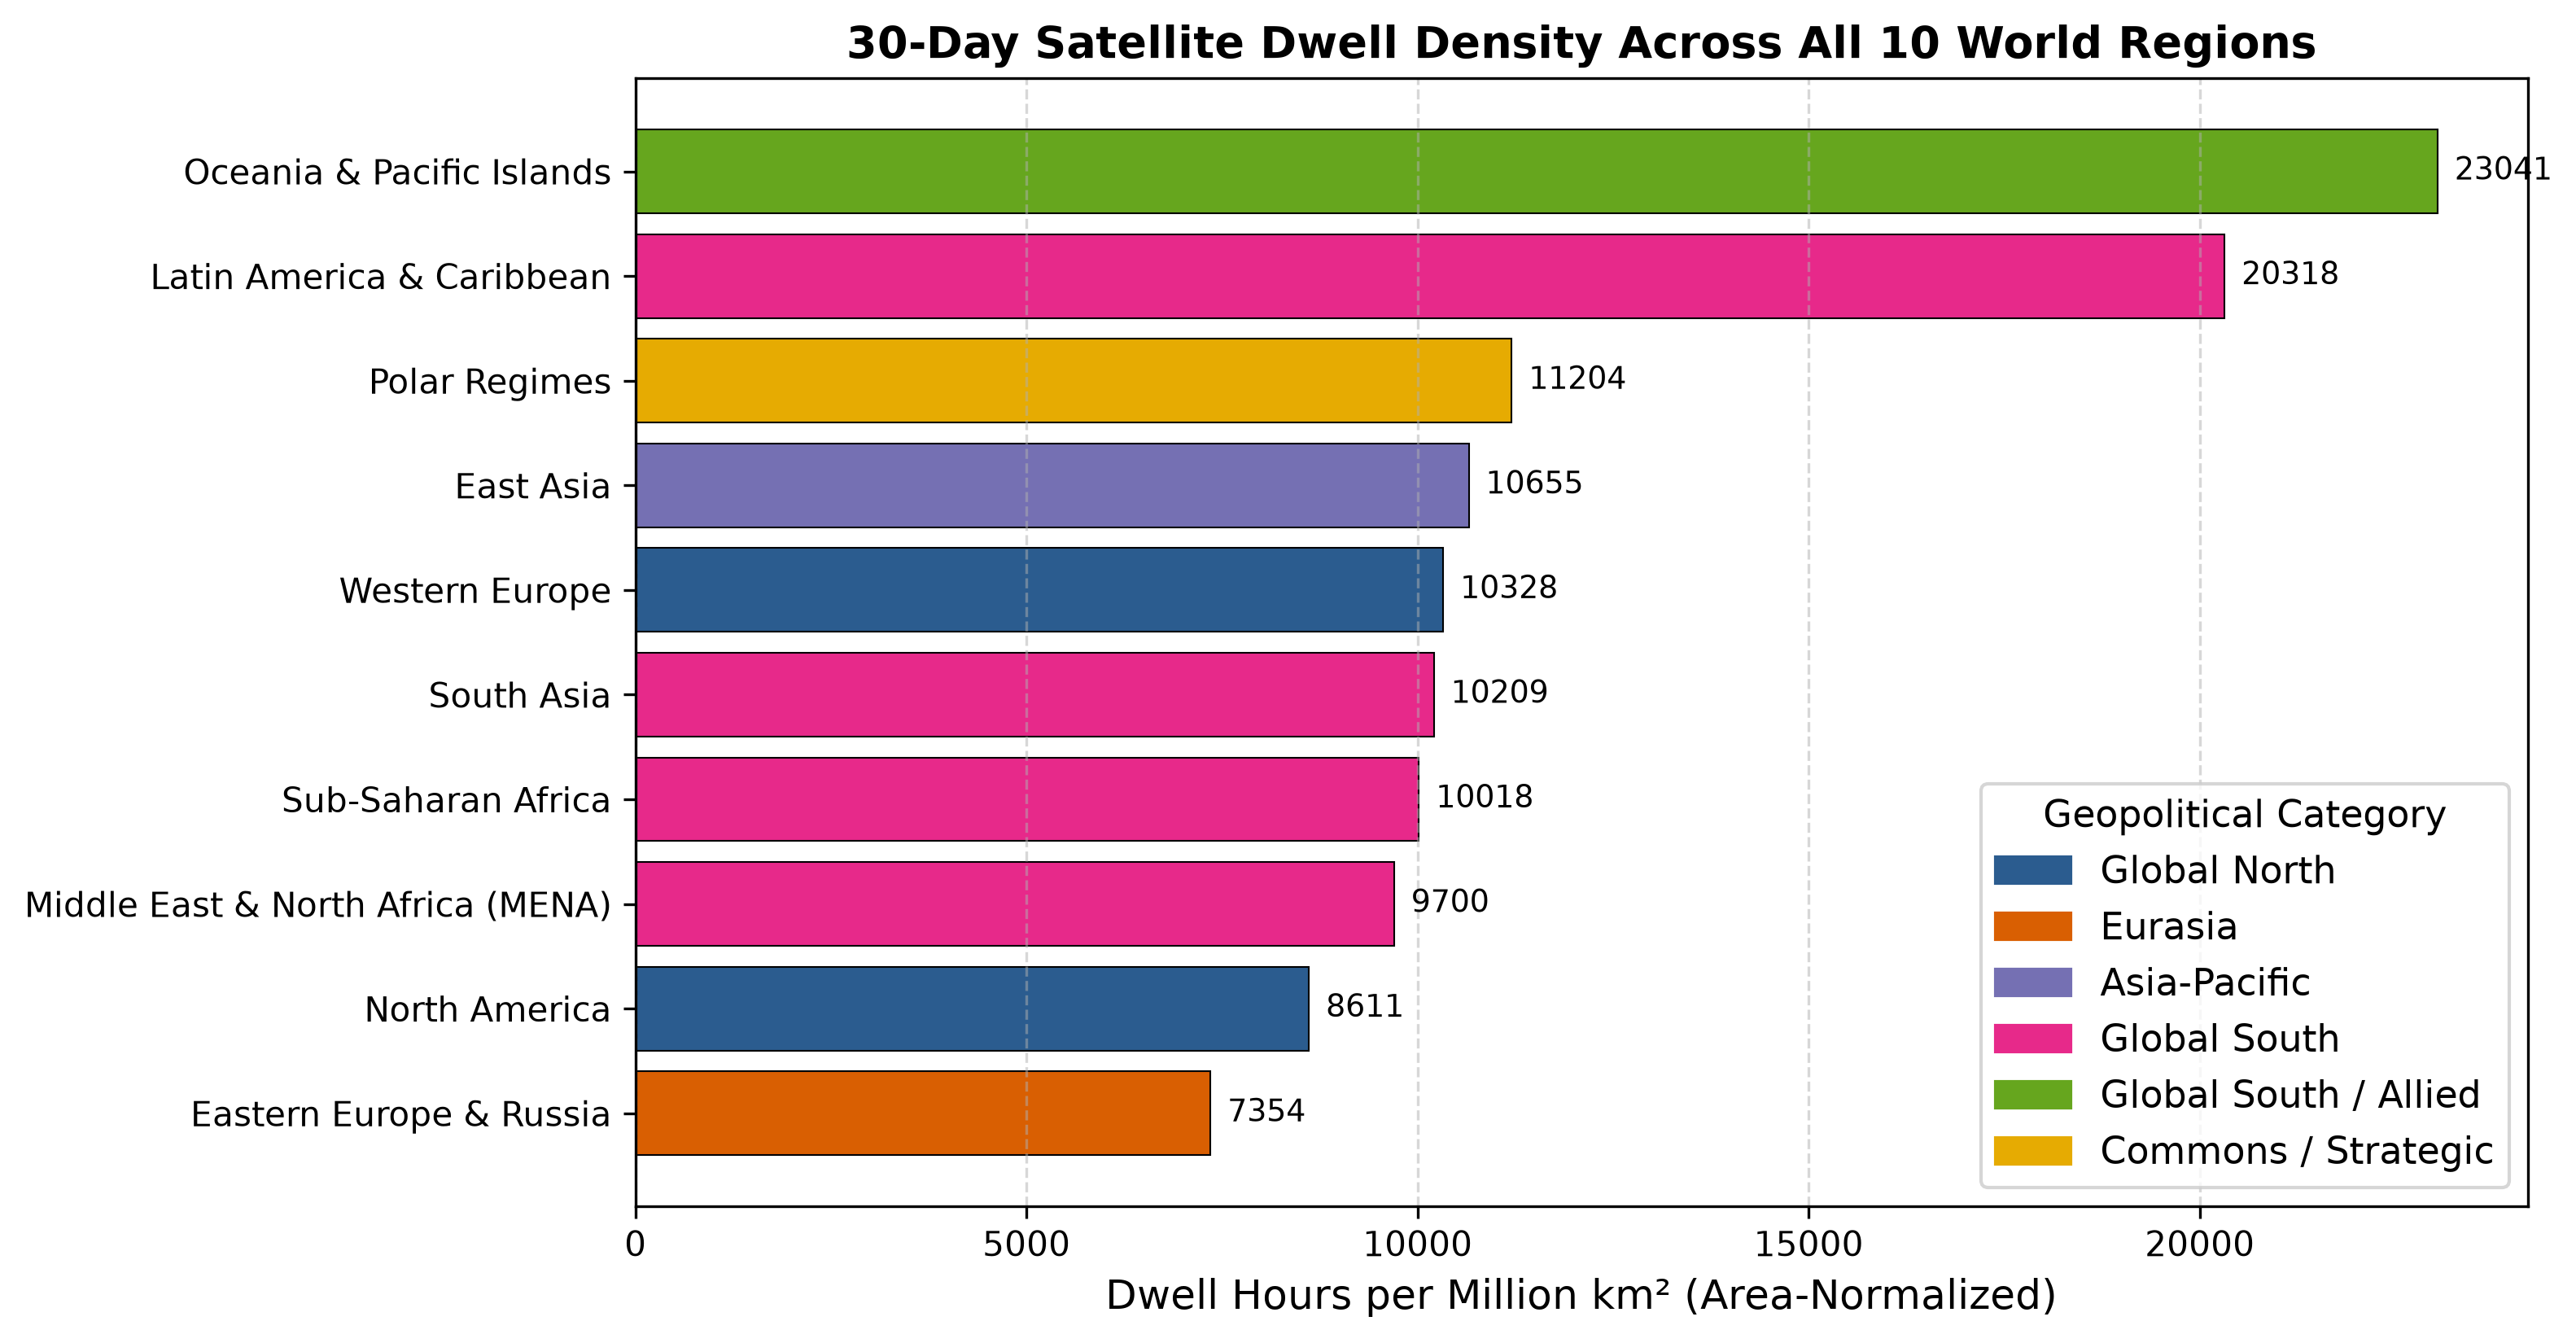

In [10]:
# Render static figure: Regional Coverage Comparison Across All 10 World Regions
fig_path = "../output/figures/regional_coverage_comparison.png"
if os.path.exists(fig_path):
    from IPython.display import Image
    display(Image(filename=fig_path))


## 6. Latitudinal Dwell Skew & Analytical Orbit Mechanics
A circular orbit with inclination $i$ exhibits a ground-track latitude density distribution governed by:
$$\frac{dt}{d\phi} = \frac{1}{\pi \sqrt{\sin^2(i) - \sin^2(\phi)}}$$
This causes satellites to dwell longer at their northern and southern turning points ($\pm i$) than near the equator. For mega-constellations deployed at $i \approx 53^\circ$ (e.g. Starlink), maximum orbital coverage is concentrated over $45^\circ\text{--}53^\circ\text{N}$ (North America, Europe, East Asia).


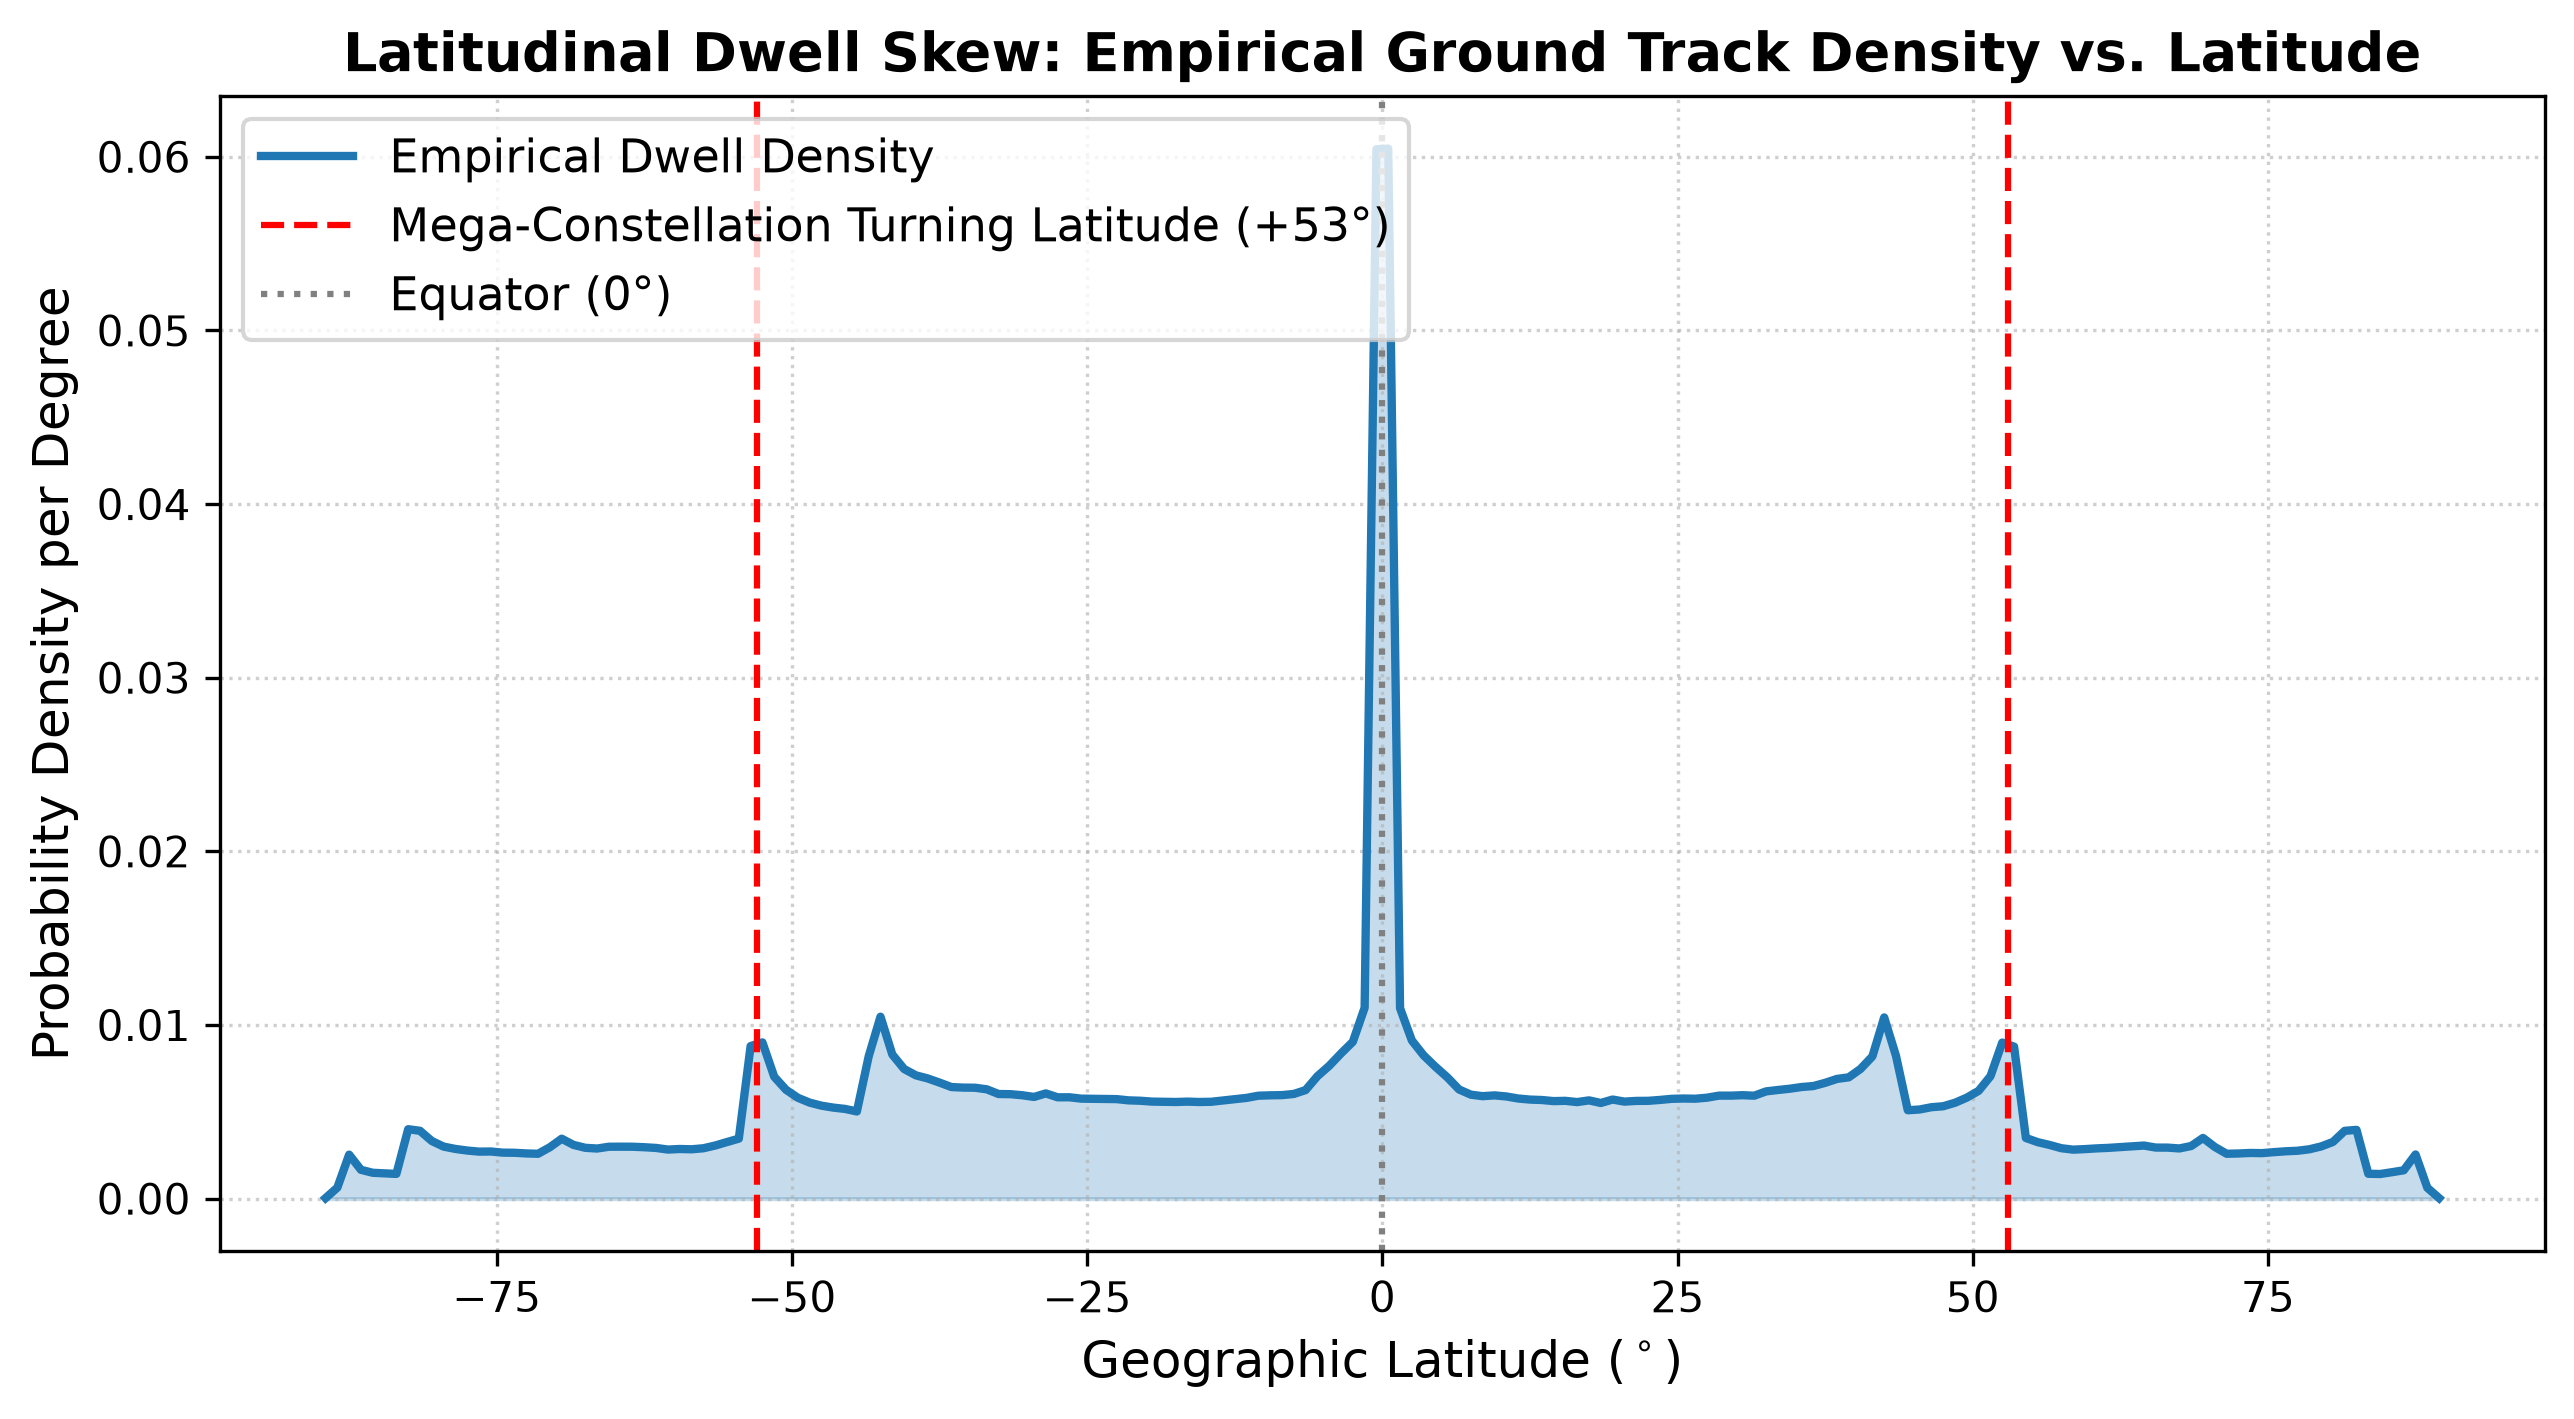

In [11]:
# Render static figure: Latitudinal Dwell Profile
fig_path = "../output/figures/latitudinal_dwell_profile.png"
if os.path.exists(fig_path):
    from IPython.display import Image
    display(Image(filename=fig_path))


## 7. Earth Observation Revisit Disparity Across World Regions
We analyze the revisit interval (hours between satellite passes) for remote sensing and reconnaissance platforms over all 10 world regions.


In [12]:
eo_revisit_df = pd.read_csv("../data/processed/earth_observation_revisit.csv")
display(eo_revisit_df)


,Region,Category,Area (M km²),Total EO Passes,Pass Density (Passes / M km²),Estimated Revisit (Hours / M km²)
0,Polar Regimes,Commons / Strategic,28.00,82650,2951.79,0.2
1,Oceania & Pacific Islands,Global South / Allied,8.50,21723,2555.65,0.3
2,Latin America & Caribbean,Global South,20.10,48032,2389.65,0.3
3,Western Europe,Global North,5.40,8727,1616.11,0.4
4,South Asia,Global South,5.10,7292,1429.80,0.5
5,Middle East & North Africa (MENA),Global South,11.10,15308,1379.10,0.5
6,Eastern Europe & Russia,Eurasia,18.00,24710,1372.78,0.5
7,North America,Global North,24.71,32431,1312.52,0.5
8,East Asia,Asia-Pacific,11.80,15480,1311.86,0.5
9,Sub-Saharan Africa,Global South,24.30,26453,1088.60,0.7


## 8. Space Debris Liability Index: Environmental Injustice in Orbit
We examine the ratio of tracked orbital debris generated relative to active operational payloads:
$$R_{\text{liability}} = \frac{N_{\text{debris}}}{N_{\text{active\_payloads}}}$$
Major space powers created the vast majority of historical debris through anti-satellite (ASAT) tests and rocket stage breakups. Emerging space programs launching small payloads into LEO must navigate these collision risks without having contributed to the debris field.


In [13]:
debris_liability_df = pd.read_csv("../data/processed/debris_liability_index.csv")
display(debris_liability_df.head(10))


,Owner,Active Payloads,Tracked Debris,Total Objects,Debris Liability Ratio
0,UNK,43,2667,2710,62.02
1,CIS,73,1,74,0.01
2,US,11653,0,11653,0.00
3,UK,663,0,663,0.00
4,PRC,465,0,465,0.00
5,JPN,56,0,56,0.00
6,IND,51,0,51,0.00
7,ESA,47,0,47,0.00
8,SES,36,0,36,0.00
9,ITSO,36,0,36,0.00


## 9. Interactive Visualizations (Plotly)
Explore the interactive 2D/3D visualizations generated by the pipeline:
- **Interactive Orbital Architecture**: Altitude vs. Inclination scatter plot.
- **Interactive Trajectory Map**: Sample ground tracks over 30 days.
- **Interactive Regional Revisit Dashboard**: Comparative coverage across all 10 world regions.


In [14]:
# Display interactive scatter plot in the notebook
fig_scatter = create_interactive_orbital_scatter(df_master, output_html="../output/interactive/interactive_orbital_scatter.html")
fig_scatter.show()


Saved interactive plot: ../output/interactive/interactive_orbital_scatter.html


## 10. Policy Synthesis & Astropolitical Conclusions

### Key Empirical Findings
1. **LEO Enclosure & Monopoly**: SpaceX (Starlink) alone commands **88.1%** of active LEO satellites, producing an HHI of **7,789.3**. The Global South combined holds less than **0.2%** of active orbital real estate.
2. **Latitudinal Market Optimization**: Inclination selection (~53°) structurally biases satellite ground presence toward affluent Global North latitudes ($45^\circ\text{--}55^\circ\text{N}$), leaving equatorial nations with thinner passes and total dependence on foreign uplink gateways.
3. **Surveillance Asymmetry**: Earth observation orbits concentrate persistent revisit capability over strategic high-income zones, while developing nations lack sovereign spaceborne monitoring for climate adaptation and disaster response.
4. **Environmental Externalities**: Debris liability ratios expose an asymmetric burden where latecomers absorb collision risks caused by great power ASAT tests and legacy launches.

### Governance Recommendations
- **Reform of the ITU "First-Come, First-Served" Doctrine**: Transition to equitable orbital spectrum allocation that reserves orbital shells and frequency slots for developing nations, reviving the equity principles of the 1976 Bogotá Declaration in LEO.
- **Orbital Carrying Capacity & Debris Fees**: Establish an international orbital management framework under UN COPUOS that levies fees on mega-constellations to fund active debris removal (ADR) and open Space Situational Awareness (SSA) data trusts for emerging space programs.
